# **PREPROCESSING**

## **INITIAL STEPS**

### REQUIREMENTS  

In [ ]:
# requirements uncomment and run if needed.
!pip install pydicom nibabel simpleitk
!pip install pyvista
!pip install skimage
!pip install Scikit-image # if above doesn't work

You should consider upgrading via the '/Users/miopc/Desktop/Data Project AI/.venv/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/miopc/Desktop/Data Project AI/.venv/bin/python3 -m pip install --upgrade pip' command.
  Using cached skimage-0.0.tar.gz (757 bytes)
    ERROR: Command errored out with exit status 1:
     command: '/Users/miopc/Desktop/Data Project AI/.venv/bin/python3' -c 'import io, os, sys, setuptools, tokenize; sys.argv[0] = '"'"'/private/var/folders/kt/5jvp1yk96ddfylx1_f15_rf00000gn/T/pip-install-oomtnbub/skimage_7c3eb9430c2242adb92f2587a8bd3ba7/setup.py'"'"'; __file__='"'"'/private/var/folders/kt/5jvp1yk96ddfylx1_f15_rf00000gn/T/pip-install-oomtnbub/skimage_7c3eb9430c2242adb92f2587a8bd3ba7/setup.py'"'"';f = getattr(tokenize, '"'"'open'"'"', open)(__file__) if os.path.exists(__file__) else io.StringIO('"'"'from setuptools import setup; setup()'"'"');code = f.read().replace('"'"'\r\n'"'"', '"'"'\n'"'"');f.close();exec(com

### REMOVE THE TRIPLE DATASET STRUCTURE


In [ ]:
def flatten_pancreas_dataset(input_root, output_root):
    """
    Copy DICOM files from TCIA Pancreas-CT structure into a flattened structure:

    From:
        input_root/PANCREAS_XXXX/<UID>/<UID>/*.dcm

    To:
        output_root/Pancreas-XXXX/*.dcm
    """

    os.makedirs(output_root, exist_ok=True)

    for patient_folder in os.listdir(input_root):
        if not patient_folder.startswith("PANCREAS_"):
            continue

        patient_number = patient_folder.split("_")[1]
        new_patient_name = f"Pancreas-{patient_number}"

        input_patient_path = os.path.join(input_root, patient_folder)
        output_patient_path = os.path.join(output_root, new_patient_name)
        os.makedirs(output_patient_path, exist_ok=True)

        # Walk through nested UID folders
        for root, _, files in os.walk(input_patient_path):
            for file in files:
                if file.endswith(".dcm"):
                    src = os.path.join(root, file)
                    dst = os.path.join(output_patient_path, file)
                    shutil.copy2(src, dst)

        print(f"Copied {patient_folder} -> {new_patient_name}")

    print("Done.")

In [ ]:
input_root = "/Users/miopc/Desktop/Data project AI/Pancreas-CT"
output_root = "/Users/miopc/Desktop/Data project AI/Pancreas-Flat"

flatten_pancreas_dataset(input_root, output_root)

Copied PANCREAS_0016 -> Pancreas-0016
Copied PANCREAS_0029 -> Pancreas-0029
Copied PANCREAS_0011 -> Pancreas-0011
Copied PANCREAS_0027 -> Pancreas-0027
Copied PANCREAS_0018 -> Pancreas-0018
Copied PANCREAS_0020 -> Pancreas-0020
Copied PANCREAS_0074 -> Pancreas-0074
Copied PANCREAS_0080 -> Pancreas-0080
Copied PANCREAS_0073 -> Pancreas-0073
Copied PANCREAS_0045 -> Pancreas-0045
Copied PANCREAS_0042 -> Pancreas-0042
Copied PANCREAS_0021 -> Pancreas-0021
Copied PANCREAS_0026 -> Pancreas-0026
Copied PANCREAS_0019 -> Pancreas-0019
Copied PANCREAS_0010 -> Pancreas-0010
Copied PANCREAS_0017 -> Pancreas-0017
Copied PANCREAS_0028 -> Pancreas-0028
Copied PANCREAS_0043 -> Pancreas-0043
Copied PANCREAS_0044 -> Pancreas-0044
Copied PANCREAS_0072 -> Pancreas-0072
Copied PANCREAS_0081 -> Pancreas-0081
Copied PANCREAS_0075 -> Pancreas-0075
Copied PANCREAS_0057 -> Pancreas-0057
Copied PANCREAS_0068 -> Pancreas-0068
Copied PANCREAS_0050 -> Pancreas-0050
Copied PANCREAS_0066 -> Pancreas-0066
Copied PANCR

### CONVERSION OF PANCREAS-CT IN NIFTI

In [ ]:
from pathlib import Path
import re
import SimpleITK as sitk
import sys


def find_dicom_leaf_dir(patient_dir: Path) -> Path:
    """
    Find the directory that actually contains the .dcm files.
    - If patient_dir contains .dcm, return patient_dir.
    - Otherwise search recursively for the first subfolder containing .dcm files.
    """
    if any(patient_dir.glob("*.dcm")):
        return patient_dir

    for sub in patient_dir.rglob("*"):
        if sub.is_dir() and any(sub.glob("*.dcm")):
            return sub

    raise FileNotFoundError(f"No .dcm files found under: {patient_dir}")


def read_dicom_series(dicom_dir: Path) -> sitk.Image:
    """
    Read a DICOM series from dicom_dir.
    If multiple series IDs exist, select the one with the most slices.
    """
    reader = sitk.ImageSeriesReader()
    series_ids = reader.GetGDCMSeriesIDs(str(dicom_dir))
    if not series_ids:
        raise RuntimeError(f"No DICOM series IDs found in: {dicom_dir}")

    best_files = None
    best_n = -1

    for sid in series_ids:
        files = reader.GetGDCMSeriesFileNames(str(dicom_dir), sid)
        if len(files) > best_n:
            best_n = len(files)
            best_files = files

    reader.SetFileNames(best_files)
    img = reader.Execute()
    return img


def convert_pancreas_ct_to_nifti(pancreas_ct_root: str | Path, output_dir: str | Path) -> None:
    """
    Convert all patients under a Pancreas-CT folder into NIfTI volumes.

    Expected input:
      pancreas_ct_root/
        PANCREAS_0001/...
        PANCREAS_0002/...
        ...

    Output:
      output_dir/
        pancreas_0001.nii.gz
        pancreas_0002.nii.gz
        ...
    """
    pancreas_ct_root = Path(pancreas_ct_root)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    patient_dirs = sorted([p for p in pancreas_ct_root.iterdir() if p.is_dir()])
    print(f"Found {len(patient_dirs)} patient folders in: {pancreas_ct_root}")

    for patient_dir in patient_dirs:
        # supports names like "PANCREAS_0004" or "PANCREAS-0004"
        m = re.search(r"(\d{4})", patient_dir.name)
        if not m:
            print(f"[SKIP] Unrecognized patient folder name: {patient_dir.name}")
            continue

        case_id = m.group(1)
        out_path = output_dir / f"pancreas_{case_id}.nii.gz"

        if out_path.exists():
            print(f"[OK] Already exists: {out_path.name}")
            continue

        try:
            dicom_dir = find_dicom_leaf_dir(patient_dir)
            img = read_dicom_series(dicom_dir)
            sitk.WriteImage(img, str(out_path))
            print(f"[DONE] {patient_dir.name} -> {out_path.name}")
        except Exception as e:
            print(f"[ERR] {patient_dir.name}: {e}")

In [ ]:
convert_pancreas_ct_to_nifti(
    r"/Users/miopc/Desktop/Data project AI/Pancreas-CT",
    r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_NIFTI"
)

Found 80 patient folders in: /Users/miopc/Desktop/Data project AI/Pancreas-CT
[DONE] PANCREAS_0001 -> pancreas_0001.nii.gz
[DONE] PANCREAS_0002 -> pancreas_0002.nii.gz
[DONE] PANCREAS_0003 -> pancreas_0003.nii.gz
[DONE] PANCREAS_0004 -> pancreas_0004.nii.gz
[DONE] PANCREAS_0005 -> pancreas_0005.nii.gz
[DONE] PANCREAS_0006 -> pancreas_0006.nii.gz
[DONE] PANCREAS_0007 -> pancreas_0007.nii.gz
[DONE] PANCREAS_0008 -> pancreas_0008.nii.gz
[DONE] PANCREAS_0009 -> pancreas_0009.nii.gz
[DONE] PANCREAS_0010 -> pancreas_0010.nii.gz
[DONE] PANCREAS_0011 -> pancreas_0011.nii.gz
[DONE] PANCREAS_0012 -> pancreas_0012.nii.gz
[DONE] PANCREAS_0013 -> pancreas_0013.nii.gz
[DONE] PANCREAS_0014 -> pancreas_0014.nii.gz
[DONE] PANCREAS_0015 -> pancreas_0015.nii.gz
[DONE] PANCREAS_0016 -> pancreas_0016.nii.gz
[DONE] PANCREAS_0017 -> pancreas_0017.nii.gz
[DONE] PANCREAS_0018 -> pancreas_0018.nii.gz
[DONE] PANCREAS_0019 -> pancreas_0019.nii.gz
[DONE] PANCREAS_0020 -> pancreas_0020.nii.gz
[DONE] PANCREAS_0021 -

### FUNCTION THAT CHECKS IF THE MASKS COINCIDE WITH THE CT-IMAGES

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk


def overlay_ct_mask_nifti(
    ct_nifti_root: str,
    mask_nifti_root: str,
    patient_id: str,
    slice_start: int,
    slice_end: int,
    step: int = 1,
    alpha: float = 0.35,
    window: tuple | None = (-100, 200),   # if CT is HU; set None if already normalized
    max_cols: int = 6,
):
    """
    Reads CT NIfTI + mask NIfTI, resamples mask into CT space, overlays selected slices.

    Expected files:
      CT:   ct_nifti_root/pancreas_XXXX.nii.gz
      Mask: mask_nifti_root/labelXXXX.nii.gz   (or adjust naming below)
    """

    ct_path = os.path.join(ct_nifti_root, f"pancreas_{patient_id}.nii.gz")
    mask_path = os.path.join(mask_nifti_root, f"label{patient_id}.nii.gz")

    if not os.path.exists(ct_path):
        raise FileNotFoundError(ct_path)
    if not os.path.exists(mask_path):
        raise FileNotFoundError(mask_path)

    # --- Read CT and mask NIfTI (geometry-aware) ---
    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    # --- Resample mask into CT grid (NN for labels) ---
    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(ct_img)
    resampler.SetInterpolator(sitk.sitkNearestNeighbor)
    resampler.SetTransform(sitk.Transform())  # identity in physical space
    resampler.SetDefaultPixelValue(0)
    mask_resampled = resampler.Execute(mask_img)

    # --- Convert to numpy (SimpleITK -> arrays are [z,y,x]) ---
    ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)       # (Z,Y,X)
    mask = sitk.GetArrayFromImage(mask_resampled).astype(np.uint8)

    # --- Slice range handling ---
    z0 = max(0, slice_start)
    z1 = min(ct.shape[0], slice_end)
    indices = list(range(z0, z1, step))
    if not indices:
        raise ValueError("Empty slice range.")

    # --- Plot ---
    n = len(indices)
    cols = min(max_cols, n)
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(3.2 * cols, 3.2 * rows))

    for i, z in enumerate(indices, start=1):
        img2d = ct[z]

        # Windowing (useful for HU CT). If your CT is already normalized, set window=None.
        if window is not None:
            lo, hi = window
            img2d = np.clip(img2d, lo, hi)

        plt.subplot(rows, cols, i)
        plt.imshow(img2d, cmap="gray")
        plt.imshow(mask[z] > 0, cmap="Reds", alpha=alpha, interpolation="nearest")
        plt.title(f"{patient_id} | slice {z}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    # --- Sanity prints ---
    print("CT path:", ct_path)
    print("Mask path:", mask_path)
    print("CT size (X,Y,Z):", ct_img.GetSize(), "spacing:", ct_img.GetSpacing())
    print("Mask size (orig):", mask_img.GetSize(), "spacing:", mask_img.GetSpacing())
    print("Mask size (resampled):", mask_resampled.GetSize(), "spacing:", mask_resampled.GetSpacing())
    print("CT numpy shape (Z,Y,X):", ct.shape, "min/max:", float(ct.min()), float(ct.max()))
    print("Mask unique values:", np.unique(mask))

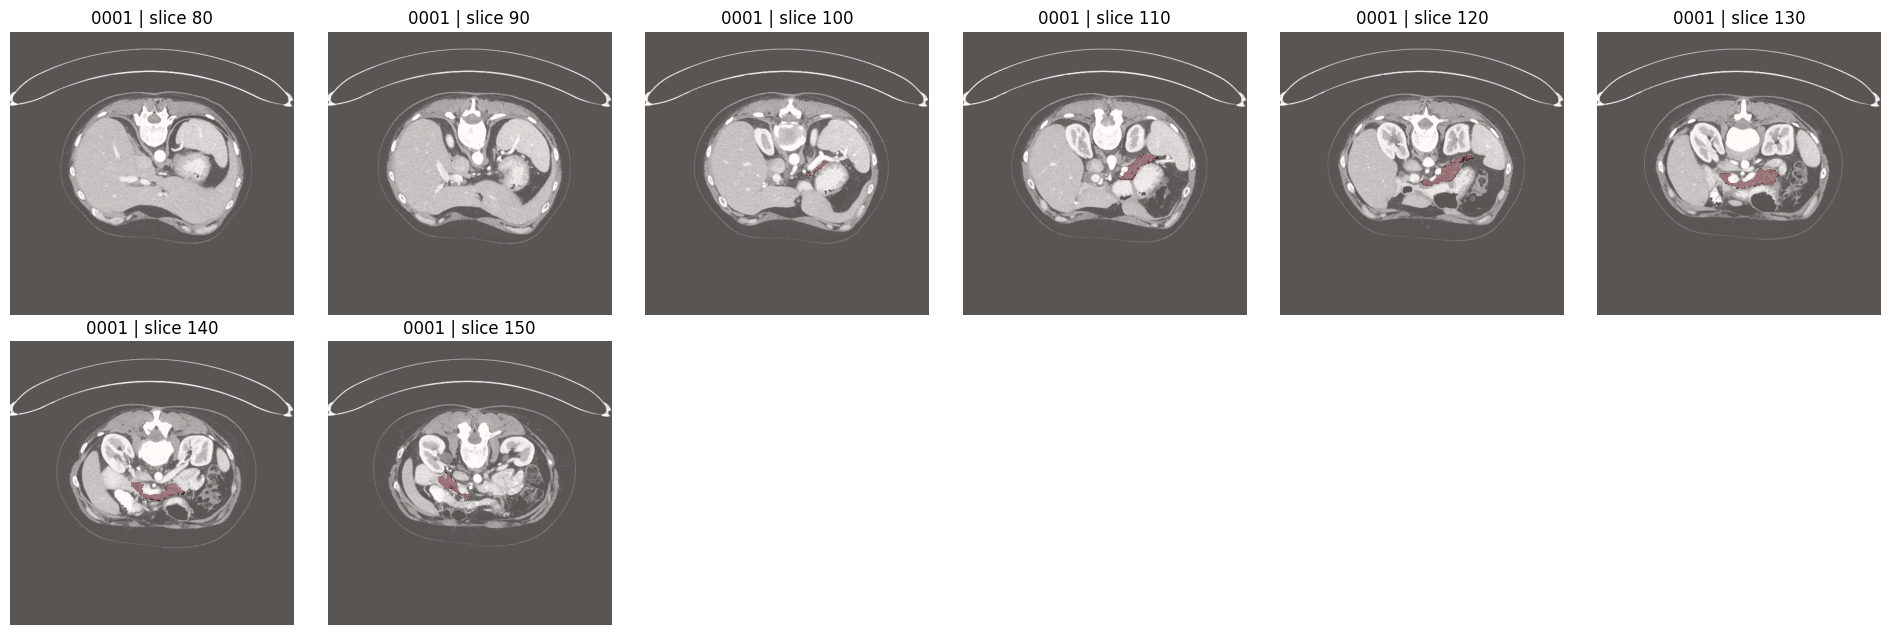

CT path: /Users/miopc/Desktop/Data project AI/PANCREAS-CT_NIFTI/pancreas_0001.nii.gz
Mask path: /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0001.nii.gz
CT size (X,Y,Z): (512, 512, 240) spacing: (0.859375, 0.859375, 1.0)
Mask size (orig): (512, 512, 240) spacing: (0.859375, 0.859375, 1.0)
Mask size (resampled): (512, 512, 240) spacing: (0.859375, 0.859375, 1.0)
CT numpy shape (Z,Y,X): (240, 512, 512) min/max: -1024.0 2421.0
Mask unique values: [0 1]


In [ ]:
overlay_ct_mask_nifti(
    ct_nifti_root=r"/Users/miopc/Desktop/Data project AI/PANCREAS-CT_NIFTI",
    mask_nifti_root=r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017",
    patient_id="0001",
    slice_start=80,
    slice_end=160,
    step=10,
    alpha=0.35,
    window=(-100, 200)  # set to None if CT is already normalized
)

In [ ]:
import os
import nibabel as nib

def check_nifti_spacing(labels_root):
    """
    Checks voxel spacing (pixdim) for each .nii.gz file
    in the labels folder.
    """

    for fname in sorted(os.listdir(labels_root)):

        if not fname.endswith(".nii.gz"):
            continue

        path = os.path.join(labels_root, fname)

        img = nib.load(path)

        # voxel spacing is stored in header pixdim[1:4]
        spacing = img.header.get_zooms()[:3]  # (dx, dy, dz)

        print(f"\n{fname}")
        print("   spacing:", spacing)
        print("   shape:  ", img.shape)

In [ ]:
labels_root = r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017"
check_nifti_spacing(labels_root)


label0001.nii.gz
   spacing: (np.float32(0.859375), np.float32(0.859375), np.float32(1.0))
   shape:   (512, 512, 240)

label0002.nii.gz
   spacing: (np.float32(0.8984375), np.float32(0.8984375), np.float32(1.0))
   shape:   (512, 512, 195)

label0003.nii.gz
   spacing: (np.float32(0.6640625), np.float32(0.6640625), np.float32(1.0))
   shape:   (512, 512, 216)

label0004.nii.gz
   spacing: (np.float32(0.8984375), np.float32(0.8984375), np.float32(1.0))
   shape:   (512, 512, 221)

label0005.nii.gz
   spacing: (np.float32(0.858), np.float32(0.858), np.float32(1.0))
   shape:   (512, 512, 210)

label0006.nii.gz
   spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(1.0))
   shape:   (512, 512, 223)

label0007.nii.gz
   spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(1.0))
   shape:   (512, 512, 201)

label0008.nii.gz
   spacing: (np.float32(0.82), np.float32(0.82), np.float32(1.0))
   shape:   (512, 512, 205)

label0009.nii.gz
   spacing: (np.float32(0.858), np.flo

In [ ]:
pancreas_nifti = r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_NIFTI"
check_nifti_spacing(pancreas_nifti)



pancreas_0001.nii.gz
   spacing: (np.float32(0.859375), np.float32(0.859375), np.float32(1.0))
   shape:   (512, 512, 240)

pancreas_0002.nii.gz
   spacing: (np.float32(0.8984375), np.float32(0.8984375), np.float32(1.0))
   shape:   (512, 512, 195)

pancreas_0003.nii.gz
   spacing: (np.float32(0.6640625), np.float32(0.6640625), np.float32(1.0))
   shape:   (512, 512, 216)

pancreas_0004.nii.gz
   spacing: (np.float32(0.8984375), np.float32(0.8984375), np.float32(1.0))
   shape:   (512, 512, 221)

pancreas_0005.nii.gz
   spacing: (np.float32(0.858), np.float32(0.858), np.float32(1.0))
   shape:   (512, 512, 210)

pancreas_0006.nii.gz
   spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(1.0))
   shape:   (512, 512, 223)

pancreas_0007.nii.gz
   spacing: (np.float32(0.9375), np.float32(0.9375), np.float32(1.0))
   shape:   (512, 512, 201)

pancreas_0008.nii.gz
   spacing: (np.float32(0.82), np.float32(0.82), np.float32(1.0))
   shape:   (512, 512, 205)

pancreas_0009.nii.gz
  

## **RESAMPLING**

In [ ]:
import os
import re
import numpy as np
import SimpleITK as sitk


def resample_ct_nii_and_mask_nii_aligned(
    ct_nifti_root: str,
    labels_root: str,
    out_ct_root: str,
    out_mask_root: str,
    target_spacing=(1.0, 1.0, 1.0),
):
    """
    For each patient:
      - Read CT NIfTI from ct_nifti_root/pancreas_XXXX.nii.gz
      - Resample CT to target_spacing with linear interpolation
      - Save CT NIfTI to out_ct_root/pancreas_XXXX.nii.gz
      - Read mask NIfTI from labels_root/labelXXXX.nii.gz
      - Resample mask onto the CT-resampled grid (nearest neighbor)
      - Save mask NIfTI to out_mask_root/labelXXXX.nii.gz  (KEEP SAME NAME)
    """

    os.makedirs(out_ct_root, exist_ok=True)
    os.makedirs(out_mask_root, exist_ok=True)

    # Collect CT NIfTI files: pancreas_XXXX.nii.gz
    ct_files = []
    pat = re.compile(r"^pancreas_(\d{4})\.nii(\.gz)?$")
    for fn in sorted(os.listdir(ct_nifti_root)):
        m = pat.match(fn)
        if m:
            ct_files.append((m.group(1), fn))

    print(f"Found {len(ct_files)} CT NIfTI files in {ct_nifti_root}")

    for patient_id, ct_fn in ct_files:
        in_ct_path = os.path.join(ct_nifti_root, ct_fn)
        in_mask_path = os.path.join(labels_root, f"label{patient_id}.nii.gz")

        if not os.path.exists(in_mask_path):
            print(f"[SKIP] {patient_id}: missing mask label{patient_id}.nii.gz")
            continue

        out_ct_path = os.path.join(out_ct_root, f"pancreas_{patient_id}.nii.gz")
        out_mask_path = os.path.join(out_mask_root, f"label{patient_id}.nii.gz")  # keep same name

        try:
            # ---------- Read CT ----------
            ct = sitk.ReadImage(in_ct_path)

            # ---------- Resample CT ----------
            orig_spacing = np.array(ct.GetSpacing(), dtype=float)   # (sx, sy, sz)
            orig_size = np.array(ct.GetSize(), dtype=int)           # (x, y, z)

            new_size = np.maximum(
                1, np.round(orig_size * (orig_spacing / np.array(target_spacing, dtype=float))).astype(int)
            ).tolist()

            ct_resampler = sitk.ResampleImageFilter()
            ct_resampler.SetOutputSpacing(tuple(target_spacing))
            ct_resampler.SetSize(new_size)
            ct_resampler.SetOutputDirection(ct.GetDirection())
            ct_resampler.SetOutputOrigin(ct.GetOrigin())
            ct_resampler.SetTransform(sitk.Transform())
            ct_resampler.SetInterpolator(sitk.sitkLinear)

            ct_arr = sitk.GetArrayFromImage(ct)
            ct_resampler.SetDefaultPixelValue(float(ct_arr.min()))
            ct_rs = ct_resampler.Execute(ct)

            # ---------- Read mask ----------
            mask = sitk.ReadImage(in_mask_path)

            # ---------- Resample MASK onto CT_rs grid ----------
            mask_resampler = sitk.ResampleImageFilter()
            mask_resampler.SetReferenceImage(ct_rs)  # guarantees alignment
            mask_resampler.SetTransform(sitk.Transform())
            mask_resampler.SetInterpolator(sitk.sitkNearestNeighbor)
            mask_resampler.SetDefaultPixelValue(0)

            mask_rs = mask_resampler.Execute(mask)
            mask_rs = sitk.Cast(mask_rs > 0, sitk.sitkUInt8)

            # ---------- Save outputs ----------
            # Optional: cast CT to float32 for stability. Remove if you want original dtype.
            ct_rs_to_save = sitk.Cast(ct_rs, sitk.sitkFloat32)

            sitk.WriteImage(ct_rs_to_save, out_ct_path)
            sitk.WriteImage(mask_rs, out_mask_path)  # saved normally, same name

            # ---------- Sanity checks ----------
            if ct_rs.GetSize() != mask_rs.GetSize():
                raise RuntimeError("Alignment check failed: CT and mask sizes differ after resampling.")
            if tuple(np.round(ct_rs.GetSpacing(), 6)) != tuple(np.round(mask_rs.GetSpacing(), 6)):
                raise RuntimeError("Alignment check failed: CT and mask spacings differ after resampling.")

            print(
                f"[OK] {patient_id} | CT size {tuple(orig_size)} -> {ct_rs.GetSize()} "
                f"| spacing {tuple(np.round(orig_spacing,3))} -> {ct_rs.GetSpacing()} | mask saved"
            )

        except Exception as e:
            print(f"[ERROR] {patient_id}: {e}")

In [ ]:
resample_ct_nii_and_mask_nii_aligned(
    ct_nifti_root=r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_NIFTI",
    labels_root=r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017",
    out_ct_root=r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm",
    out_mask_root=r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels_1mm",
    target_spacing=(1.0, 1.0, 1.0),
)

Found 80 CT NIfTI files in /Users/miopc/Desktop/Data project AI/Pancreas-CT_NIFTI
[OK] 0001 | CT size (np.int64(512), np.int64(512), np.int64(240)) -> (440, 440, 240) | spacing (np.float64(0.859), np.float64(0.859), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0002 | CT size (np.int64(512), np.int64(512), np.int64(195)) -> (460, 460, 195) | spacing (np.float64(0.898), np.float64(0.898), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0003 | CT size (np.int64(512), np.int64(512), np.int64(216)) -> (340, 340, 216) | spacing (np.float64(0.664), np.float64(0.664), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0004 | CT size (np.int64(512), np.int64(512), np.int64(221)) -> (460, 460, 221) | spacing (np.float64(0.898), np.float64(0.898), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0005 | CT size (np.int64(512), np.int64(512), np.int64(210)) -> (439, 439, 210) | spacing (np.float64(0.858), np.float64(0.858), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK

NiftiImageIO (0x10b1609e0): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0007.nii.gz has unexpected scales in sform

NiftiImageIO (0x10b1609e0): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0007.nii.gz has unexpected scales in sform



[OK] 0007 | CT size (np.int64(512), np.int64(512), np.int64(201)) -> (480, 480, 201) | spacing (np.float64(0.938), np.float64(0.938), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0008 | CT size (np.int64(512), np.int64(512), np.int64(205)) -> (420, 420, 205) | spacing (np.float64(0.82), np.float64(0.82), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0009 | CT size (np.int64(512), np.int64(512), np.int64(196)) -> (439, 439, 196) | spacing (np.float64(0.858), np.float64(0.858), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0010 | CT size (np.int64(512), np.int64(512), np.int64(206)) -> (475, 475, 206) | spacing (np.float64(0.928), np.float64(0.928), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0011 | CT size (np.int64(512), np.int64(512), np.int64(221)) -> (462, 462, 221) | spacing (np.float64(0.902), np.float64(0.902), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0012 | CT size (np.int64(512), np.int64(512), np.int64(214)) -> (500, 500, 214) | 

NiftiImageIO (0x10b154610): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0027.nii.gz has unexpected scales in sform

NiftiImageIO (0x10b154610): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0027.nii.gz has unexpected scales in sform



[OK] 0027 | CT size (np.int64(512), np.int64(512), np.int64(205)) -> (420, 420, 205) | spacing (np.float64(0.82), np.float64(0.82), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0028 | CT size (np.int64(512), np.int64(512), np.int64(206)) -> (460, 460, 206) | spacing (np.float64(0.898), np.float64(0.898), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0029 | CT size (np.int64(512), np.int64(512), np.int64(199)) -> (400, 400, 199) | spacing (np.float64(0.781), np.float64(0.781), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0030 | CT size (np.int64(512), np.int64(512), np.int64(310)) -> (470, 470, 310) | spacing (np.float64(0.918), np.float64(0.918), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0031 | CT size (np.int64(512), np.int64(512), np.int64(310)) -> (400, 400, 310) | spacing (np.float64(0.781), np.float64(0.781), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved


NiftiImageIO (0x10cb053b0): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0032.nii.gz has unexpected scales in sform

NiftiImageIO (0x10cb053b0): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0032.nii.gz has unexpected scales in sform



[OK] 0032 | CT size (np.int64(512), np.int64(512), np.int64(233)) -> (500, 500, 233) | spacing (np.float64(0.977), np.float64(0.977), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0033 | CT size (np.int64(512), np.int64(512), np.int64(310)) -> (380, 380, 310) | spacing (np.float64(0.742), np.float64(0.742), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0034 | CT size (np.int64(512), np.int64(512), np.int64(205)) -> (400, 400, 205) | spacing (np.float64(0.782), np.float64(0.782), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0035 | CT size (np.int64(512), np.int64(512), np.int64(227)) -> (440, 440, 227) | spacing (np.float64(0.859), np.float64(0.859), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0036 | CT size (np.int64(512), np.int64(512), np.int64(223)) -> (420, 420, 223) | spacing (np.float64(0.82), np.float64(0.82), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0037 | CT size (np.int64(512), np.int64(512), np.int64(198)) -> (380, 380, 198) | 

NiftiImageIO (0x10b159120): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0045.nii.gz has unexpected scales in sform

NiftiImageIO (0x10b159120): /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels-02-05-2017/label0045.nii.gz has unexpected scales in sform



[OK] 0045 | CT size (np.int64(512), np.int64(512), np.int64(216)) -> (480, 480, 216) | spacing (np.float64(0.938), np.float64(0.938), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0046 | CT size (np.int64(512), np.int64(512), np.int64(198)) -> (400, 400, 198) | spacing (np.float64(0.782), np.float64(0.782), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0047 | CT size (np.int64(512), np.int64(512), np.int64(201)) -> (420, 420, 201) | spacing (np.float64(0.82), np.float64(0.82), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0048 | CT size (np.int64(512), np.int64(512), np.int64(206)) -> (480, 480, 206) | spacing (np.float64(0.938), np.float64(0.938), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0049 | CT size (np.int64(512), np.int64(512), np.int64(222)) -> (460, 460, 222) | spacing (np.float64(0.898), np.float64(0.898), np.float64(1.0)) -> (1.0, 1.0, 1.0) | mask saved
[OK] 0050 | CT size (np.int64(512), np.int64(512), np.int64(310)) -> (360, 360, 310) | 

In [ ]:
out_ct_root = r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm"
check_nifti_spacing(out_ct_root)



pancreas_0001.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (440, 440, 240)

pancreas_0002.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (460, 460, 195)

pancreas_0003.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (340, 340, 216)

pancreas_0004.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (460, 460, 221)

pancreas_0005.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (439, 439, 210)

pancreas_0006.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (480, 480, 223)

pancreas_0007.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (480, 480, 201)

pancreas_0008.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
   shape:   (420, 420, 205)

pancreas_0009.nii.gz
   spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  

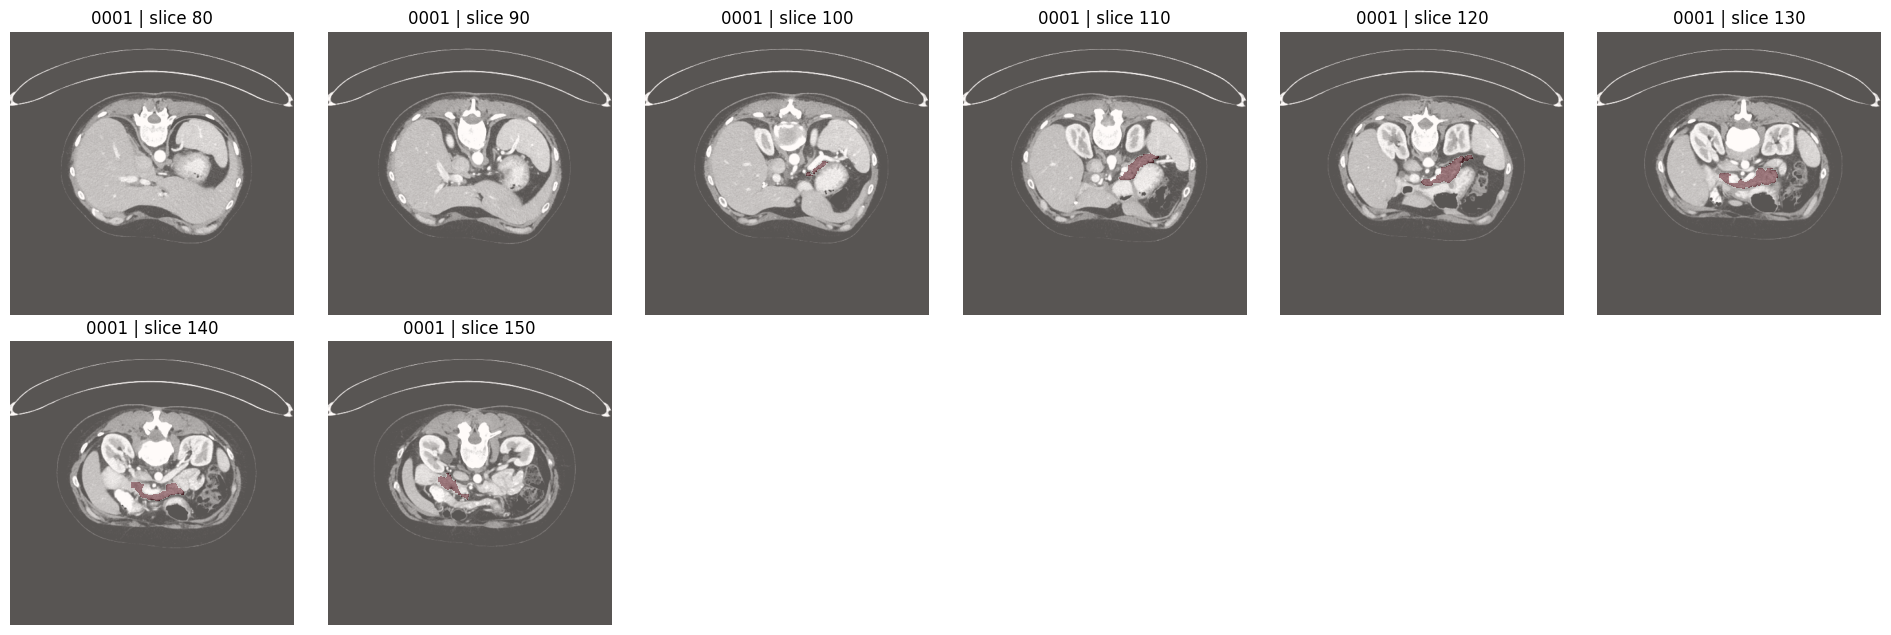

CT path: /Users/miopc/Desktop/Data project AI/PANCREAS-CT_1mm/pancreas_0001.nii.gz
Mask path: /Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels_1mm/label0001.nii.gz
CT size (X,Y,Z): (440, 440, 240) spacing: (1.0, 1.0, 1.0)
Mask size (orig): (440, 440, 240) spacing: (1.0, 1.0, 1.0)
Mask size (resampled): (440, 440, 240) spacing: (1.0, 1.0, 1.0)
CT numpy shape (Z,Y,X): (240, 440, 440) min/max: -1024.0 2026.0
Mask unique values: [0 1]


In [ ]:
overlay_ct_mask_nifti(
    ct_nifti_root=r"/Users/miopc/Desktop/Data project AI/PANCREAS-CT_1mm",
    mask_nifti_root=r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels_1mm",
    patient_id="0001",
    slice_start=80,
    slice_end=160,
    step=10,
    alpha=0.35,
    window=(-100, 200)  # set to None if CT is already normalized
)

## **CLIPPING**

Below: histogram is of the CT image intensities (voxel HU values) from the resampled CT volumes.
We do it to decide if we want to clip the values or not.
We ususally clip becuase it reduces outliers, stabilizes gradient, improves convergence.
Also because we do not want the network dynamic dominated by backround.

In [ ]:
!pip install tqdm

Found CT files: 80
DATASET HU RANGE (1mm): min=-2048.0, max=3071.0


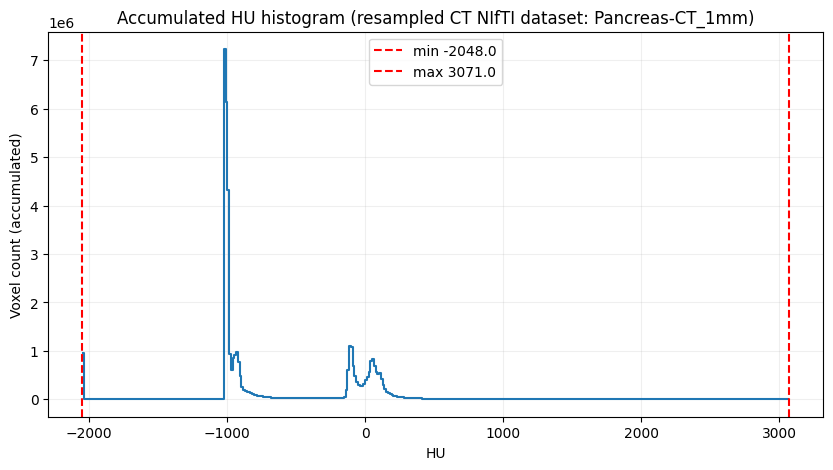

In [ ]:
# HU range + histogram for RESAMPLED CT NIfTI dataset (Pancreas-CT_1mm)
import os, glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

CT_1MM_DIR = r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm"

bins = 400
sample_voxels_per_volume = 500_000  # sample per 3D volume to keep it fast

paths = sorted(glob.glob(os.path.join(CT_1MM_DIR, "pancreas_*.nii.gz")))
print("Found CT files:", len(paths))
if len(paths) == 0:
    raise RuntimeError(f"No pancreas_XXXX.nii.gz files found in {CT_1MM_DIR}")

# 1) global min/max
global_min = float("inf")
global_max = float("-inf")

for p in paths:
    vol = nib.load(p).get_fdata(dtype=np.float32)
    vmin = float(np.min(vol))
    vmax = float(np.max(vol))
    global_min = min(global_min, vmin)
    global_max = max(global_max, vmax)

print(f"DATASET HU RANGE (1mm): min={global_min:.1f}, max={global_max:.1f}")

# 2) histogram accumulation (sampling)
hist_min = max(global_min, -2048.0)
hist_max = min(global_max, 3071.0)
if hist_min >= hist_max:
    hist_min, hist_max = global_min, global_max

bin_edges = np.linspace(hist_min, hist_max, bins + 1)
hist_counts = np.zeros(bins, dtype=np.int64)

rng = np.random.default_rng(42)

for p in paths:
    vol = nib.load(p).get_fdata(dtype=np.float32).ravel()
    if vol.size > sample_voxels_per_volume:
        idx = rng.choice(vol.size, size=sample_voxels_per_volume, replace=False)
        vol = vol[idx]
    counts, _ = np.histogram(vol, bins=bin_edges)
    hist_counts += counts

# 3) plot
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(10, 5))
plt.plot(bin_centers, hist_counts, drawstyle="steps-mid")
plt.xlabel("HU")
plt.ylabel("Voxel count (accumulated)")
plt.title("Accumulated HU histogram (resampled CT NIfTI dataset: Pancreas-CT_1mm)")
plt.grid(alpha=0.2)
plt.axvline(global_min, color="red", linestyle="--", label=f"min {global_min:.1f}")
plt.axvline(global_max, color="red", linestyle="--", label=f"max {global_max:.1f}")
plt.legend()
plt.show()

Graph intepretation:  The intensity range from  −2048 HU to 3071 HU.

 The largest peak is around −1000 HU, corresponding to air, which occupies a substantial portion of each volume. A second broad concentration appears between roughly −200 and 200 HU, representing soft tissues, including the pancreas.

 Smaller peaks above 0 HU correspond to denser structures such as bone.

 The extreme values at both ends are sparse and represent outliers or background regions rather than clinically relevant pancreas tissue.

 Important: typical reference values

 Air ≈ −1000 HU

Fat ≈ −100 to −50 HU

Soft tissues (muscle, organs like pancreas) ≈ −50 to 150 HU

Bone ≈ 300 to 1500+ HU

Metal / very dense materials > 2000 HU

Based on the graph we do decide to clipping the HU values:
-200 and 300. this is becasue


We preserve all relevant soft tissue information.

We remove irrelevant air and extreme high-density values.

We reduce the impact of rare outliers.

We stabilize the input distribution before normalization.

In [ ]:
import os
import numpy as np
import SimpleITK as sitk
import nibabel as nib

BASE = "/Users/miopc/Desktop/Data project AI"
RES_CT_DICOM_DIR = os.path.join(BASE, "Pancreas-Flat_0_87mm_DICOM_Indep")   # DICOM folders (current)
RES_CT_NII_DIR   = os.path.join(BASE, "Pancreas-Flat_0_87mm_NIFTI")        # optional NIfTI folder (may not exist)
OUT_DIR = os.path.join(BASE, "Pancreas-Flat_0_87mm_CLIPPED_NII")
os.makedirs(OUT_DIR, exist_ok=True)

def load_ct_from_dicom_folder(folder):
    reader = sitk.ImageSeriesReader()
    sids = reader.GetGDCMSeriesIDs(folder)
    if not sids:
        raise RuntimeError(f"No DICOM series in {folder}")
    sid = sids[0]
    files = reader.GetGDCMSeriesFileNames(folder, sid)
    reader.SetFileNames(files)
    img = reader.Execute()
    arr_z_y_x = sitk.GetArrayFromImage(img).astype(np.float32)  # (z,y,x)
    spacing = img.GetSpacing()
    origin = img.GetOrigin()
    direction = np.array(img.GetDirection()).reshape(3,3)
    # build affine that maps voxel indices (i,j,k) in (x,y,z) ordering
    affine = np.eye(4, dtype=np.float32)
    affine[:3,:3] = direction @ np.diag(spacing)
    affine[:3,3] = origin
    # convert array to (x,y,z) ordering expected by nibabel
    arr_x_y_z = np.transpose(arr_z_y_x, (2,1,0))
    return arr_x_y_z, affine

def load_ct_from_nifti(patient_folder):
    nifti_path = os.path.join(RES_CT_NII_DIR, patient_folder, f"ct_resampled_{patient_folder.split('-')[1]}.nii.gz")
    if not os.path.exists(nifti_path):
        raise FileNotFoundError(nifti_path)
    img = nib.load(nifti_path)
    data = img.get_fdata().astype(np.float32)   # nib returns (x,y,z)
    return data, img.affine

def clip_and_save_all(clip_min=-200.0, clip_max=300.0):
    patients = sorted([d for d in os.listdir(RES_CT_DICOM_DIR) if d.startswith("Pancreas-")])
    for p in patients:
        try:
            # Prefer NIfTI if present, else use DICOM folder
            try:
                vol, affine = load_ct_from_nifti(p)
            except Exception:
                vol, affine = load_ct_from_dicom_folder(os.path.join(RES_CT_DICOM_DIR, p))
        except Exception as e:
            print(f"[SKIP] {p}: {e}")
            continue

        # clip only
        vol_clipped = np.clip(vol, clip_min, clip_max).astype(np.float32)

        # save as NIfTI; keep per-patient subfolder
        out_patient_dir = os.path.join(OUT_DIR, p)
        os.makedirs(out_patient_dir, exist_ok=True)
        out_path = os.path.join(out_patient_dir, f"ct_clipped_{p.split('-')[1]}.nii.gz")
        nib.save(nib.Nifti1Image(vol_clipped, affine), out_path)
        print(f"[OK] {p} -> {out_path}")

# Run with the recommended window:
clip_and_save_all(clip_min=-200.0, clip_max=300.0)

[OK] Pancreas-0001 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0001/ct_clipped_0001.nii.gz
[OK] Pancreas-0002 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0002/ct_clipped_0002.nii.gz
[OK] Pancreas-0003 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0003/ct_clipped_0003.nii.gz
[OK] Pancreas-0004 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0004/ct_clipped_0004.nii.gz
[OK] Pancreas-0005 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0005/ct_clipped_0005.nii.gz
[OK] Pancreas-0006 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0006/ct_clipped_0006.nii.gz
[OK] Pancreas-0007 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancreas-0007/ct_clipped_0007.nii.gz
[OK] Pancreas-0008 -> /Users/miopc/Desktop/Data project AI/Pancreas-Flat_0_87mm_CLIPPED_NII/Pancr

In [ ]:
import os, glob #ew
import numpy as np
import nibabel as nib

BASE = "/Users/miopc/Desktop/Data project AI"

# INPUT: resampled CT NIfTIs produced by resample_ct_nii_and_mask_nii_aligned
# e.g. /Users/.../Data project AI/Pancreas-CT_1mm/pancreas_0001.nii.gz
RESAMPLED_CT_DIR = os.path.join(BASE, "Pancreas-CT_1mm")

# OUTPUT: clipped CT NIfTIs (same naming, new folder)
OUT_DIR = os.path.join(BASE, "Pancreas-CT_1mm_CLIPPED")
os.makedirs(OUT_DIR, exist_ok=True)

def clip_and_save_all(clip_min=-200.0, clip_max=300.0):
    ct_paths = sorted(glob.glob(os.path.join(RESAMPLED_CT_DIR, "pancreas_*.nii.gz")))
    if len(ct_paths) == 0:
        raise RuntimeError(f"No pancreas_*.nii.gz found in: {RESAMPLED_CT_DIR}")

    for in_path in ct_paths:
        try:
            img = nib.load(in_path)
            vol = img.get_fdata(dtype=np.float32)          # (x,y,z)
            vol_clipped = np.clip(vol, clip_min, clip_max).astype(np.float32)

            out_path = os.path.join(OUT_DIR, os.path.basename(in_path))  # same filename
            nib.save(nib.Nifti1Image(vol_clipped, img.affine, img.header), out_path)

            print(f"[OK] {os.path.basename(in_path)} -> {out_path}")
        except Exception as e:
            print(f"[SKIP] {os.path.basename(in_path)}: {e}")

# Run:
clip_and_save_all(clip_min=-200.0, clip_max=300.0)

[OK] pancreas_0001.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0001.nii.gz
[OK] pancreas_0002.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0002.nii.gz
[OK] pancreas_0003.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0003.nii.gz
[OK] pancreas_0004.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0004.nii.gz
[OK] pancreas_0005.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0005.nii.gz
[OK] pancreas_0006.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0006.nii.gz
[OK] pancreas_0007.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0007.nii.gz
[OK] pancreas_0008.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0008.nii.gz
[OK] pancreas_0009.nii.gz -> /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/pancreas_0009.nii.gz
[

Check hu min and max values after clipping

In [ ]:
# Sanity check: clipping bounds for the NEW pipeline (NIfTI-only, one file per patient)
import os, glob
import numpy as np
import nibabel as nib

BASE = "/Users/miopc/Desktop/Data project AI"

# This must match the output folder from the NEW clipping script
CLIPPED_DIR = os.path.join(BASE, "Pancreas-CT_1mm_CLIPPED")

clip_min, clip_max = -200.0, 300.0

paths = sorted(glob.glob(os.path.join(CLIPPED_DIR, "pancreas_*.nii.gz")))
print("Clipped volumes found:", len(paths))
if len(paths) == 0:
    raise RuntimeError(f"No pancreas_*.nii.gz found in {CLIPPED_DIR}")

bad = []
mins, maxs = [], []

for p in paths:
    data = nib.load(p).get_fdata(dtype=np.float32)
    vmin, vmax = float(data.min()), float(data.max())
    mins.append(vmin); maxs.append(vmax)

    # tiny tolerance for float roundoff
    if vmin < clip_min - 1e-3 or vmax > clip_max + 1e-3:
        bad.append((os.path.basename(p), vmin, vmax))

print(f"Global after-clipping min={min(mins):.2f}, max={max(maxs):.2f}")
print("Files outside clip range:", len(bad))

if bad:
    print("First few offending files:")
    for item in bad[:10]:
        print("BAD:", item)

Clipped volumes found: 80
Global after-clipping min=-200.00, max=300.00
Files outside clip range: 0


We confirm that For each patient:

All ~250 slices were read

Combined into a 3D volume

Every voxel inside that 3D volume was clipped to [-200, 300]

Then saved as one new file

Histograms of HU after clipping

Clipped CT files found: 80


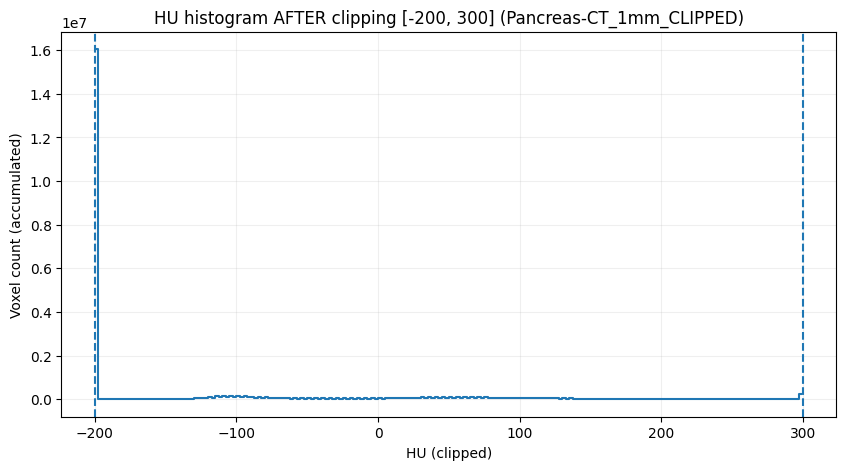

In [ ]:
# HU histogram AFTER clipping for the NEW pipeline (NIfTI-only, one file per patient)
import os, glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

BASE = "/Users/miopc/Desktop/Data project AI"
CLIPPED_DIR = os.path.join(BASE, "Pancreas-CT_1mm_CLIPPED")  # output of the new clipping step

bins = 200
sample_voxels_per_volume = 300_000
hist_min, hist_max = -200.0, 300.0

paths = sorted(glob.glob(os.path.join(CLIPPED_DIR, "pancreas_*.nii.gz")))
print("Clipped CT files found:", len(paths))
if len(paths) == 0:
    raise RuntimeError(f"No pancreas_*.nii.gz found in {CLIPPED_DIR}")

bin_edges = np.linspace(hist_min, hist_max, bins + 1)
hist_counts = np.zeros(bins, dtype=np.int64)

rng = np.random.default_rng(42)

for path in paths:
    data = nib.load(path).get_fdata(dtype=np.float32).ravel()
    if data.size > sample_voxels_per_volume:
        data = data[rng.choice(data.size, size=sample_voxels_per_volume, replace=False)]
    c, _ = np.histogram(data, bins=bin_edges)
    hist_counts += c

bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(10, 5))
plt.plot(bin_centers, hist_counts, drawstyle="steps-mid")
plt.xlabel("HU (clipped)")
plt.ylabel("Voxel count (accumulated)")
plt.title("HU histogram AFTER clipping [-200, 300] (Pancreas-CT_1mm_CLIPPED)")
plt.grid(alpha=0.2)
plt.axvline(-200, linestyle="--")
plt.axvline(300, linestyle="--")
plt.show()

## **NORMALIZATION**



The spikes at -200 and 300 are extremely large (millions of voxels).
So the y-axis automatically scales to something like 1e7.

Compared to that, the soft tissue region (which is actually important) is much smaller in magnitude — so visually it looks almost flat near zero.
it is not zero. It’s just small compared to the giant boundary spikes.

now we standardize: we first try z score
We standardize to make the data easier for the neural network to learn from.

After clipping, values are still between -200 and 300, which is a large range.

Standardization:

Centers the data around 0

Scales it to have unit variance (std = 1)

Makes training more stable and faster

Clipping removes extreme outliers.
Standardization rescales the remaining values so the model trains efficiently.

### Sample mean and standard deviation

estimate dataset mean μ and std σ from sampled voxels of the clipped NIfTIs, save μ/σ; 2) apply x_norm = (x - μ)/σ to every clipped volume and save normalized NIfTIs.

In [ ]:
# Cell A (NEW pipeline): estimate dataset mean and std from CLIPPED CT_1mm NIfTIs (sampling)
import os, glob, json
import numpy as np
import nibabel as nib

BASE = "/Users/miopc/Desktop/Data project AI"
CLIPPED_DIR = os.path.join(BASE, "Pancreas-CT_1mm_CLIPPED")   # new clipping output folder
stats_out = os.path.join(CLIPPED_DIR, "clip_norm_stats.json")

paths = sorted(glob.glob(os.path.join(CLIPPED_DIR, "pancreas_*.nii.gz")))
print("Clipped CT files found:", len(paths))
if len(paths) == 0:
    raise RuntimeError(f"No pancreas_*.nii.gz found in {CLIPPED_DIR}")

sample_voxels_per_volume = 300_000  # per 3D volume
rng = np.random.default_rng(42)

acc_sum = 0.0
acc_sum_sq = 0.0
acc_count = 0

for p in paths:
    data = nib.load(p).get_fdata(dtype=np.float32).ravel()
    if data.size > sample_voxels_per_volume:
        data = data[rng.choice(data.size, size=sample_voxels_per_volume, replace=False)]

    acc_sum += float(data.sum())
    acc_sum_sq += float((data**2).sum())
    acc_count += data.size

mean = acc_sum / acc_count
var = (acc_sum_sq / acc_count) - (mean**2)
std = float(np.sqrt(max(var, 1e-12)))

with open(stats_out, "w") as f:
    json.dump({"mean": float(mean), "std": float(std), "sampled_voxels": int(acc_count)}, f, indent=2)

print(f"Saved stats to {stats_out}")
print(f"Estimated mean={mean:.6f}, std={std:.6f}, total_sampled_voxels={acc_count:,}")

Clipped CT files found: 80
Saved stats to /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CLIPPED/clip_norm_stats.json
Estimated mean=-127.770976, std=119.885917, total_sampled_voxels=24,000,000


In [ ]:
# Cell B (NEW pipeline): normalize all clipped CT_1mm volumes using saved mean/std and save
import os, glob, json
import numpy as np
import nibabel as nib

BASE = "/Users/miopc/Desktop/Data project AI"
CLIPPED_DIR = os.path.join(BASE, "Pancreas-CT_1mm_CLIPPED")          # input clipped NIfTIs
OUT_NORM    = os.path.join(BASE, "Pancreas-CT_1mm_NORMALIZED")       # output normalized NIfTIs
os.makedirs(OUT_NORM, exist_ok=True)

# Load stats computed in Cell A
stats_path = os.path.join(CLIPPED_DIR, "clip_norm_stats.json")
with open(stats_path, "r") as f:
    stats = json.load(f)

mean, std = float(stats["mean"]), float(stats["std"])
print("Using mean, std =", mean, std)

paths = sorted(glob.glob(os.path.join(CLIPPED_DIR, "pancreas_*.nii.gz")))
print("Clipped CT files found:", len(paths))
if len(paths) == 0:
    raise RuntimeError(f"No pancreas_*.nii.gz found in {CLIPPED_DIR}")

# Normalize and save (one file per patient)
for p in paths:
    img = nib.load(p)
    data = img.get_fdata(dtype=np.float32)        # (x,y,z)
    norm = (data - mean) / std                    # z-score standardization

    out_path = os.path.join(OUT_NORM, os.path.basename(p).replace("pancreas_", "ct_norm_"))
    nib.save(nib.Nifti1Image(norm.astype(np.float32), img.affine, img.header), out_path)
    print("[OK]", out_path)

# Quick verification (sample first 50 files)
s = 0.0
s2 = 0.0
cnt = 0

check_paths = sorted(glob.glob(os.path.join(OUT_NORM, "ct_norm_*.nii.gz")))[:50]
for p in check_paths:
    d = nib.load(p).get_fdata(dtype=np.float32).ravel()
    s += float(d.sum())
    s2 += float((d**2).sum())
    cnt += d.size

mean_est = s / cnt
std_est = float(np.sqrt(s2 / cnt - mean_est**2))
print("Approx sample mean,std:", mean_est, std_est)

Using mean, std = -127.77097608333334 119.88591664319428
Clipped CT files found: 80
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0001.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0002.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0003.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0004.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0005.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0006.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0007.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0008.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0009.nii.gz
[OK] /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_NORMALIZED/ct_norm_0010.nii.gz
[OK] /Users/miopc/Desktop/

histograms of the hu values after normalization

Normalized volumes found: 80


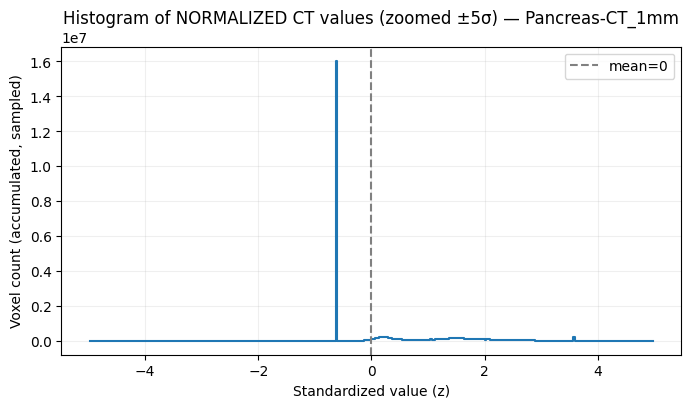

Estimated sample mean, std (from first 50 files): 0.02147687040269375 1.0163626670837402


In [ ]:
# Plot histogram of NORMALIZED volumes only (NEW pipeline: one file per patient)
import os, glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

BASE = "/Users/miopc/Desktop/Data project AI"
NORM_DIR = os.path.join(BASE, "Pancreas-CT_1mm_NORMALIZED")  # output from the NEW normalization step

paths = sorted(glob.glob(os.path.join(NORM_DIR, "ct_norm_*.nii.gz")))
print("Normalized volumes found:", len(paths))
if len(paths) == 0:
    raise RuntimeError(f"No normalized files found in {NORM_DIR}; run normalization first.")

# sampling and histogram settings
sample_voxels_per_volume = 300_000
rng = np.random.default_rng(42)
bins = 300
xlim = (-5.0, 5.0)   # zoom window for main mass

# accumulate histogram
bin_edges = np.linspace(xlim[0], xlim[1], bins + 1)
hist_counts = np.zeros(bins, dtype=np.int64)

for p in paths:
    data = nib.load(p).get_fdata(dtype=np.float32).ravel()
    if data.size > sample_voxels_per_volume:
        data = data[rng.choice(data.size, size=sample_voxels_per_volume, replace=False)]

    # zoom window for plotting
    data = data[(data >= xlim[0]) & (data <= xlim[1])]
    c, _ = np.histogram(data, bins=bin_edges)
    hist_counts += c

centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(8, 4))
plt.plot(centers, hist_counts, drawstyle="steps-mid")
plt.xlabel("Standardized value (z)")
plt.ylabel("Voxel count (accumulated, sampled)")
plt.title("Histogram of NORMALIZED CT values (zoomed ±5σ) — Pancreas-CT_1mm")
plt.axvline(0.0, linestyle="--", color="gray", label="mean=0")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

# quick numeric check (sample first 50 files)
sample_list = []
for p in paths[:50]:
    d = nib.load(p).get_fdata(dtype=np.float32).ravel()
    if d.size > sample_voxels_per_volume:
        d = d[rng.choice(d.size, size=sample_voxels_per_volume, replace=False)]
    sample_list.append(d)

sample_total = np.concatenate(sample_list)
print("Estimated sample mean, std (from first 50 files):", float(sample_total.mean()), float(sample_total.std()))

mean ≈ 0.021
std ≈ 1.016
 (sampling noise) suggests normalization worked

 the spike are the clipped values at -200 that became all the same z score. we do not have a spike becasue at the clipped value 300 we have far fewer voxels ( we can see that also in the graph before this one) therefore no spike at 300.

 Air/background dominates the volume (huge), so the -200 pile is enormous. Voxels >300 (bone/contrast/artifacts) are a much smaller fraction in abdominal CT, so the 300 spike is tiny in comparison and gets visually “buried” near the x-axis.

  for better intepretation we create an histogram removing the cliped backround



in this histogram we are seeing the real soft tissue distribution

Clipped files: 80
Norm files: 80
Matched pairs: 80


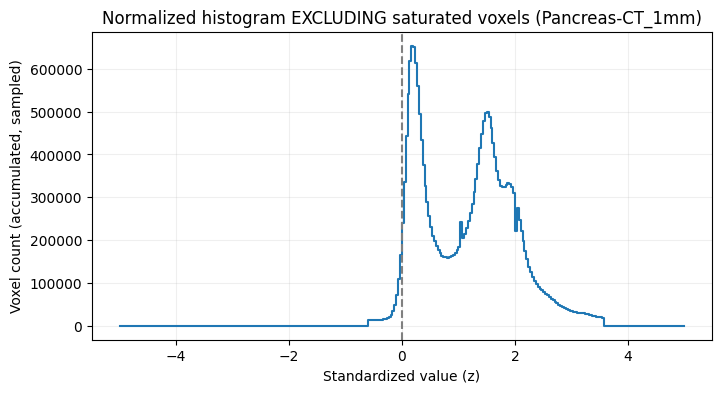

In [ ]:
# Normalized histogram EXCLUDING saturated (clipped) voxels — NEW pipeline
import os, glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

BASE = "/Users/miopc/Desktop/Data project AI"
CLIPPED_DIR = os.path.join(BASE, "Pancreas-CT_1mm_CLIPPED")      # pancreas_XXXX.nii.gz
NORM_DIR    = os.path.join(BASE, "Pancreas-CT_1mm_NORMALIZED")   # ct_norm_XXXX.nii.gz

clipped_paths = sorted(glob.glob(os.path.join(CLIPPED_DIR, "pancreas_*.nii.gz")))
norm_paths    = sorted(glob.glob(os.path.join(NORM_DIR, "ct_norm_*.nii.gz")))

print("Clipped files:", len(clipped_paths))
print("Norm files:", len(norm_paths))
if len(clipped_paths) == 0 or len(norm_paths) == 0:
    raise RuntimeError("Missing clipped or normalized files. Run clipping + normalization first.")

# match by patient id (robust, instead of zip order)
def pid_from_name(fn):
    # pancreas_0001.nii.gz -> 0001 ; ct_norm_0001.nii.gz -> 0001
    base = os.path.basename(fn)
    digits = "".join([c for c in base if c.isdigit()])
    return digits[-4:]  # last 4 digits are the case id

clip_map = {pid_from_name(p): p for p in clipped_paths}
norm_map = {pid_from_name(p): p for p in norm_paths}
common_ids = sorted(set(clip_map) & set(norm_map))

print("Matched pairs:", len(common_ids))
if len(common_ids) == 0:
    raise RuntimeError("No matching clipped/normalized pairs found (check filenames).")

bins = 300
xlim = (-5, 5)
sample_voxels_per_volume = 300_000
rng = np.random.default_rng(42)

edges = np.linspace(xlim[0], xlim[1], bins + 1)
counts = np.zeros(bins, dtype=np.int64)

CLIP_MIN, CLIP_MAX = -200.0, 300.0

for pid in common_ids:
    cp = clip_map[pid]
    npth = norm_map[pid]

    cdata = nib.load(cp).get_fdata(dtype=np.float32).ravel()
    ndata = nib.load(npth).get_fdata(dtype=np.float32).ravel()

    # exclude saturated voxels (exactly clipped values)
    keep = (cdata > CLIP_MIN) & (cdata < CLIP_MAX)
    ndata = ndata[keep]

    if ndata.size == 0:
        continue

    if ndata.size > sample_voxels_per_volume:
        ndata = ndata[rng.choice(ndata.size, size=sample_voxels_per_volume, replace=False)]

    # plot window only
    ndata = ndata[(ndata >= xlim[0]) & (ndata <= xlim[1])]
    c, _ = np.histogram(ndata, bins=edges)
    counts += c

centers = 0.5 * (edges[:-1] + edges[1:])

plt.figure(figsize=(8, 4))
plt.plot(centers, counts, drawstyle="steps-mid")
plt.xlabel("Standardized value (z)")
plt.ylabel("Voxel count (accumulated, sampled)")
plt.title("Normalized histogram EXCLUDING saturated voxels (Pancreas-CT_1mm)")
plt.axvline(0, linestyle="--", color="gray")
plt.grid(alpha=0.2)
plt.show()

## **CROPPING**

Code to use  the masks to estimate where the pancreas usually sits in the x–y plane, then suggests a fixed crop centered there.

In [ ]:
import os
import glob
import numpy as np
import nibabel as nib
from tqdm import tqdm

MASK_DIR = r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels_1mm"
TARGET_PAD = 512

def calculate_global_pancreas_center(mask_folder):
    mask_paths = sorted(glob.glob(os.path.join(mask_folder, "*.nii.gz")))

    all_patient_centers = []

    print(f"Analisi in corso su {len(mask_paths)} volumi...")

    for path in tqdm(mask_paths):
        mask_obj = nib.load(path)
        mask_data = mask_obj.get_fdata() # Solitamente (X, Y, Z) o (Z, Y, X)

        orig_w, orig_h = mask_data.shape[0], mask_data.shape[1]

        pad_x_offset = (TARGET_PAD - orig_w) // 2
        pad_y_offset = (TARGET_PAD - orig_h) // 2

        coords = np.argwhere(mask_data > 0)

        if coords.size > 0:

            mean_x_orig = coords[:, 0].mean()
            mean_y_orig = coords[:, 1].mean()

            center_x_512 = mean_x_orig + pad_x_offset
            center_y_512 = mean_y_orig + pad_y_offset

            all_patient_centers.append([center_x_512, center_y_512])

    if not all_patient_centers:
        return None, None

    global_center = np.mean(all_patient_centers, axis=0)

    return global_center[0], global_center[1]

avg_x, avg_y = calculate_global_pancreas_center(MASK_DIR)

print("\n" + "="*30)
print(f"RISULTATO CALCOLO (su base {TARGET_PAD}x{TARGET_PAD})")
print(f"Centro Medio X: {avg_x:.2f}")
print(f"Centro Medio Y: {avg_y:.2f}")
print("="*30)
print(f"Per un crop 256x256, i range di pixel sarebbero:")
print(f"X: [{int(avg_x - 128)} : {int(avg_x + 128)}]")
print(f"Y: [{int(avg_y - 128)} : {int(avg_y + 128)}]")

Analisi in corso su 80 volumi...


100%|██████████| 80/80 [00:16<00:00,  5.00it/s]


RISULTATO CALCOLO (su base 512x512)
Centro Medio X: 276.19
Centro Medio Y: 277.59
Per un crop 256x256, i range di pixel sarebbero:
X: [148 : 404]
Y: [149 : 405]


Code that takes your already-resampled 1mm CT + 1mm mask volumes, then pads and crops them to a fixed 256×256 field-of-view, while keeping CT and mask aligned.

In [ ]:
import os
import re
import numpy as np
import SimpleITK as sitk


def pad_and_fixed_crop_aligned_1mm(
    ct_1mm_root: str,
    mask_1mm_root: str,
    out_ct_root: str,
    out_mask_root: str,
    target_spacing=(1.0, 1.0, 1.0),   # keep for sanity checks / metadata
    target_pad=512,
    crop_x=(148, 404),               # [start, end) -> 256 px
    crop_y=(149, 405),               # [start, end) -> 256 px
    mask_name_mode: str = "overwrite",  # "overwrite" or "suffix"
    mask_suffix: str = "_crop256",
):
    """
    Pipeline (1mm NIfTI -> 1mm NIfTI), NO RESAMPLING:

      Input (already resampled to 1mm and aligned):
        - CT:   ct_1mm_root/pancreas_XXXX.nii.gz
        - Mask: mask_1mm_root/labelXXXX.nii.gz

      Steps:
        1) Read CT + mask
        2) (Optional sanity) verify spacing ~ target_spacing
        3) Pad both to target_pad x target_pad in-plane (Y,X) in NumPy (arrays are [Z,Y,X])
        4) Crop fixed in-plane window to 256x256 using crop_y/crop_x
        5) Update origin to account for pad+crop shift (physical space)
        6) Save CT + mask as NIfTI:
           - CT:   out_ct_root/pancreas_XXXX.nii.gz
           - Mask: out_mask_root/labelXXXX.nii.gz (overwrite) or labelXXXX{suffix}.nii.gz (suffix)
    """

    if mask_name_mode not in ("overwrite", "suffix"):
        raise ValueError("mask_name_mode must be 'overwrite' or 'suffix'")

    os.makedirs(out_ct_root, exist_ok=True)
    os.makedirs(out_mask_root, exist_ok=True)

    # collect CT files pancreas_XXXX.nii.gz
    ct_files = []
    pat = re.compile(r"^pancreas_(\d{4})\.nii(\.gz)?$")
    for fn in sorted(os.listdir(ct_1mm_root)):
        m = pat.match(fn)
        if m:
            ct_files.append((m.group(1), fn))

    print(f"Found {len(ct_files)} CT (1mm) NIfTI files in {ct_1mm_root}")

    for patient_id, ct_fn in ct_files:
        in_ct_path = os.path.join(ct_1mm_root, ct_fn)
        in_mask_path = os.path.join(mask_1mm_root, f"label{patient_id}.nii.gz")

        if not os.path.exists(in_mask_path):
            print(f"[SKIP] {patient_id}: missing mask label{patient_id}.nii.gz")
            continue

        out_ct_path = os.path.join(out_ct_root, f"pancreas_{patient_id}.nii.gz")
        if mask_name_mode == "suffix":
            out_mask_path = os.path.join(out_mask_root, f"label{patient_id}{mask_suffix}.nii.gz")
        else:
            out_mask_path = os.path.join(out_mask_root, f"label{patient_id}.nii.gz")

        try:
            # 1) READ CT + MASK (already 1mm)
            ct_1mm = sitk.ReadImage(in_ct_path)
            mask_1mm = sitk.ReadImage(in_mask_path)

            # 2) Basic sanity checks (optional but helpful)
            ct_sp = tuple(np.round(ct_1mm.GetSpacing(), 6))
            mk_sp = tuple(np.round(mask_1mm.GetSpacing(), 6))
            tgt_sp = tuple(np.round(np.array(target_spacing, dtype=float), 6))
            if ct_sp != tgt_sp:
                print(f"[WARN] {patient_id}: CT spacing {ct_sp} != target {tgt_sp}")
            if mk_sp != tgt_sp:
                print(f"[WARN] {patient_id}: MASK spacing {mk_sp} != target {tgt_sp}")

            # 3) PAD + CROP in NumPy (arrays are [Z,Y,X])
            ct_arr = sitk.GetArrayFromImage(ct_1mm).astype(np.float32)        # (Z,Y,X)
            mask_arr = sitk.GetArrayFromImage(mask_1mm).astype(np.uint8)      # (Z,Y,X)

            z_dim, h, w = ct_arr.shape

            ph = (target_pad - h) // 2
            pw = (target_pad - w) // 2

            pad_top = max(ph, 0)
            pad_bottom = max(target_pad - h - pad_top, 0)
            pad_left = max(pw, 0)
            pad_right = max(target_pad - w - pad_left, 0)

            ct_min = float(ct_arr.min())
            ct_p = np.pad(
                ct_arr,
                ((0, 0), (pad_top, pad_bottom), (pad_left, pad_right)),
                mode="constant",
                constant_values=ct_min,
            )
            mask_p = np.pad(
                mask_arr,
                ((0, 0), (pad_top, pad_bottom), (pad_left, pad_right)),
                mode="constant",
                constant_values=0,
            )

            # Crop (array order: [Z, Y, X])
            ct_cropped_arr = ct_p[:, crop_y[0]:crop_y[1], crop_x[0]:crop_x[1]]
            mask_cropped_arr = mask_p[:, crop_y[0]:crop_y[1], crop_x[0]:crop_x[1]]

            # 4) Convert back to SimpleITK + update metadata (origin shift)
            final_ct = sitk.GetImageFromArray(ct_cropped_arr.astype(np.float32))
            final_mask = sitk.GetImageFromArray(mask_cropped_arr.astype(np.uint8))

            # Origin update (in physical space):
            # net shift (pixels) = crop_start - pad_left/top
            shift_x = (crop_x[0] - pad_left) * target_spacing[0]
            shift_y = (crop_y[0] - pad_top) * target_spacing[1]

            new_origin = list(ct_1mm.GetOrigin())
            new_origin[0] += shift_x
            new_origin[1] += shift_y

            for img in (final_ct, final_mask):
                img.SetSpacing(ct_1mm.GetSpacing())
                img.SetDirection(ct_1mm.GetDirection())
                img.SetOrigin(tuple(new_origin))

            # 5) Save outputs
            sitk.WriteImage(final_ct, out_ct_path)
            sitk.WriteImage(sitk.Cast(final_mask > 0, sitk.sitkUInt8), out_mask_path)

            print(f"[OK] {patient_id} | Pad({target_pad})+Crop({crop_y},{crop_x}) -> saved")

        except Exception as e:
            print(f"[ERROR] {patient_id}: {e}")


# --------- Example coherent call (your latest paths) ---------
pad_and_fixed_crop_aligned_1mm(
    ct_1mm_root=r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm",
    mask_1mm_root=r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels_1mm",
    out_ct_root=r"/Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm_CROP256",
    out_mask_root=r"/Users/miopc/Desktop/Data project AI/TCIA_pancreas_labels_1mm_CROP256",
    target_spacing=(1.0, 1.0, 1.0),
    target_pad=512,
    crop_x=(148, 404),
    crop_y=(149, 405),
    mask_name_mode="overwrite",
)

Found 80 CT (1mm) NIfTI files in /Users/miopc/Desktop/Data project AI/Pancreas-CT_1mm
[OK] 0001 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0002 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0003 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0004 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0005 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0006 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0007 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0008 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0009 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0010 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0011 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0012 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0013 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0014 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0015 | Pad(512)+Crop((149, 405),(148, 404)) -> saved
[OK] 0016 | Pad(512)+Crop((149, 405),(148, 4